In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

Saving Final_Data.csv to Final_Data (1).csv


In [ ]:
df = pd.read_csv("Final_Data.csv")
df.head()

,District,Year,Season,Normal_Rainfall,Actual_Rainfall,Departure_Percent,Crop,Area,Production,Yield,Total_Claim_Paid,Total_Farmer_Benefits
0,Akola,2020,Kharif,693.7,587.2,-15.35,Soybean,2166.00,2656.00,1226.0,5977.0,6486
1,Akola,2020,Rabi,78.4,52.8,-32.65,Gram,842.71,970.08,1151.0,55.0,111
2,Nagpur,2020,Kharif,1072.5,1001.0,-6.67,Soybean,1557.00,626.00,402.0,1010.0,4861
3,Nagpur,2020,Rabi,81.9,48.9,-40.29,Gram,655.35,928.43,1417.0,5.0,60
4,Nashik,2020,Kharif,707.1,780.3,10.35,Soybean,796.00,1557.00,1956.0,6020.0,32975


In [ ]:
df.shape

(40, 12)

In [ ]:
df.columns

Index(['District', 'Year', 'Season', 'Normal_Rainfall', 'Actual_Rainfall',
       'Departure_Percent', 'Crop', 'Area', 'Production', 'Yield',
       'Total_Claim_Paid', 'Total_Farmer_Benefits'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
District,0
Year,0
Season,0
Normal_Rainfall,0
Actual_Rainfall,0
Departure_Percent,0
Crop,0
Area,0
Production,0
Yield,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   District               40 non-null     object 
 1   Year                   40 non-null     int64  
 2   Season                 40 non-null     object 
 3   Normal_Rainfall        40 non-null     float64
 4   Actual_Rainfall        40 non-null     float64
 5   Departure_Percent      40 non-null     float64
 6   Crop                   40 non-null     object 
 7   Area                   40 non-null     float64
 8   Production             40 non-null     float64
 9   Yield                  40 non-null     float64
 10  Total_Claim_Paid       40 non-null     float64
 11  Total_Farmer_Benefits  40 non-null     int64  
dtypes: float64(7), int64(2), object(3)
memory usage: 3.9+ KB


In [ ]:
df.describe()

,Year,Normal_Rainfall,Actual_Rainfall,Departure_Percent,Area,Production,Yield,Total_Claim_Paid,Total_Farmer_Benefits
count,40.00000,40.00000,40.000000,40.000000,40.000000,40.000000,40.00000,40.000000,40.000000
mean,2022.00000,472.62500,470.397500,-1.716500,963.388000,1216.344750,1336.14300,5894.275000,32083.275000
std,1.43223,402.46215,420.903866,37.113817,636.140258,867.404234,587.96464,15712.348023,55849.671271
min,2020.00000,78.40000,19.700000,-75.950000,232.000000,169.400000,402.00000,1.000000,23.000000
25%,2021.00000,89.30000,76.200000,-28.387500,492.667500,669.337500,983.18750,70.000000,432.000000
50%,2022.00000,409.45000,369.250000,-5.430000,861.790000,1068.440000,1190.10000,613.500000,4462.000000
75%,2023.00000,760.85000,796.425000,12.087500,1171.000000,1324.545000,1629.07500,5987.750000,36905.750000
max,2024.00000,1072.50000,1527.300000,117.210000,2467.230000,3876.670000,2822.00000,96882.000000,262637.000000


In [ ]:
df["District"].unique()

array(['Akola', 'Nagpur', 'Nashik', 'Pune'], dtype=object)

In [ ]:
df["Crop"].unique()

array(['Soybean', 'Gram'], dtype=object)

In [ ]:
df["Season"].unique()

array(['Kharif', 'Rabi'], dtype=object)

In [ ]:
df["District"].value_counts()

,count
District,
Akola,10
Nagpur,10
Nashik,10
Pune,10


In [ ]:
district_yield = df.groupby("District")["Yield"].mean()

print(district_yield)

District
Akola     1219.493
Nagpur    1130.821
Nashik    1213.431
Pune      1780.827
Name: Yield, dtype: float64


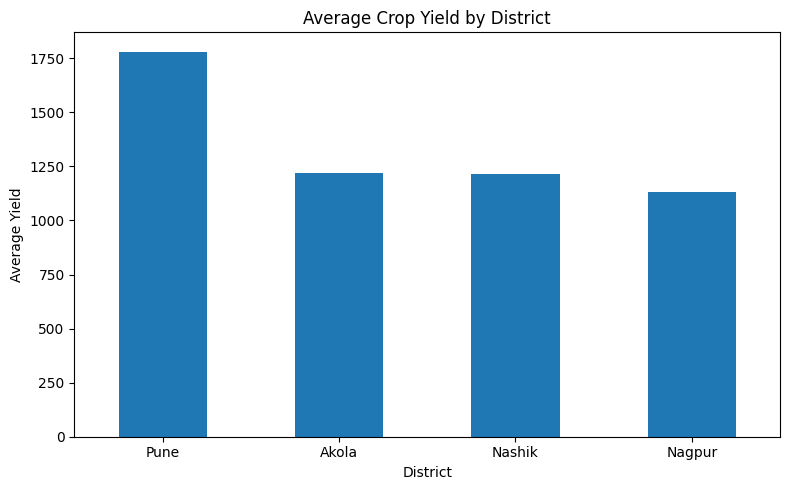

In [ ]:
district_yield = df.groupby("District")["Yield"].mean().sort_values(ascending=False)

plt.figure(figsize=(8,5))
district_yield.plot(kind="bar")

plt.title("Average Crop Yield by District")
plt.xlabel("District")
plt.ylabel("Average Yield")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

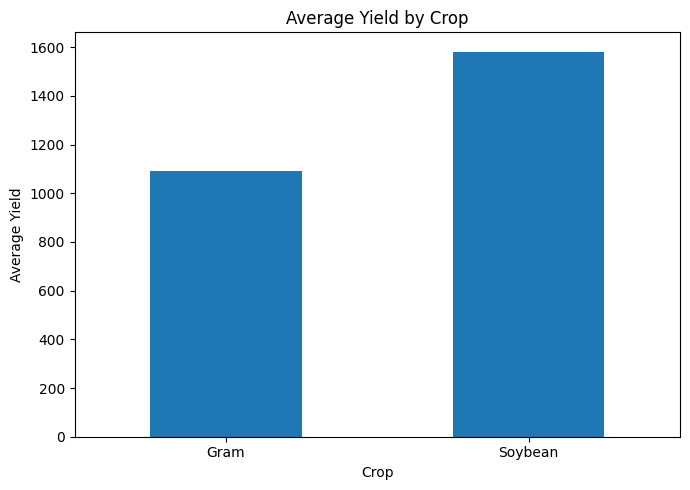

In [ ]:
crop_yield = df.groupby("Crop")["Yield"].mean()

plt.figure(figsize=(7,5))
crop_yield.plot(kind="bar")

plt.title("Average Yield by Crop")
plt.xlabel("Crop")
plt.ylabel("Average Yield")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

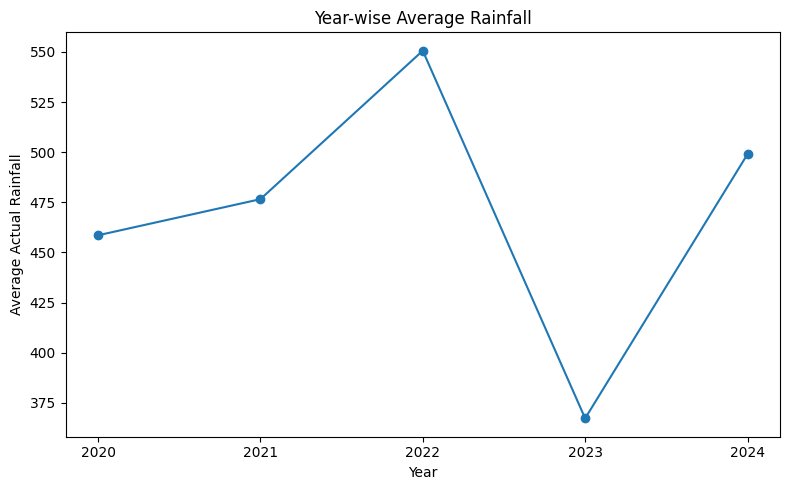

In [ ]:
year_rainfall = df.groupby("Year")["Actual_Rainfall"].mean()

plt.figure(figsize=(8,5))
plt.plot(year_rainfall.index, year_rainfall.values, marker="o")

plt.title("Year-wise Average Rainfall")
plt.xlabel("Year")
plt.ylabel("Average Actual Rainfall")
plt.xticks(year_rainfall.index)

plt.tight_layout()
plt.show()


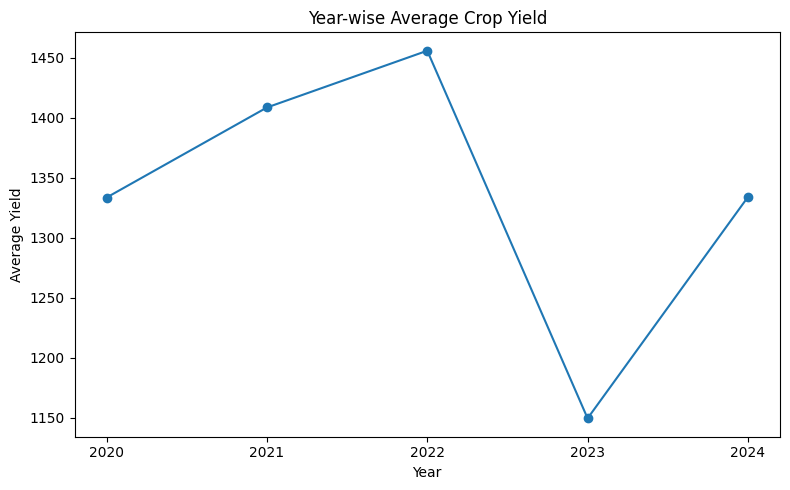

In [ ]:
year_yield = df.groupby("Year")["Yield"].mean()

plt.figure(figsize=(8,5))
plt.plot(year_yield.index, year_yield.values, marker="o")

plt.title("Year-wise Average Crop Yield")
plt.xlabel("Year")
plt.ylabel("Average Yield")
plt.xticks(year_yield.index)

plt.tight_layout()
plt.show()


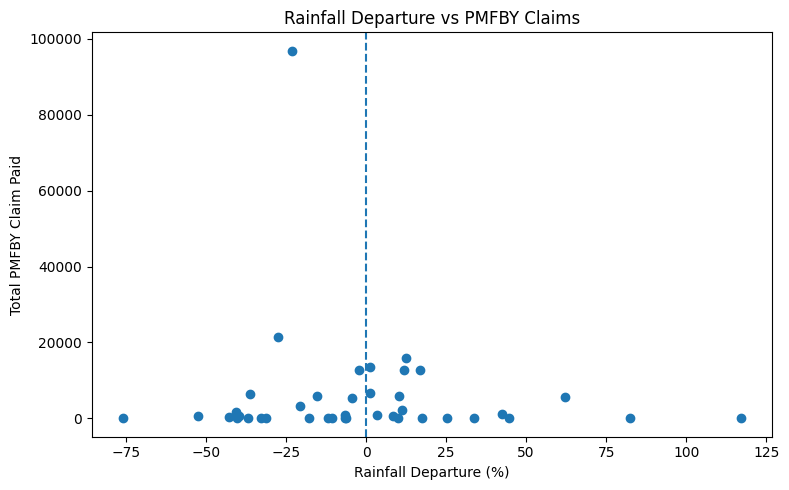

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["Departure_Percent"],
    df["Total_Claim_Paid"]
)

plt.title("Rainfall Departure vs PMFBY Claims")
plt.xlabel("Rainfall Departure (%)")
plt.ylabel("Total PMFBY Claim Paid")

plt.axvline(0, linestyle="--")

plt.tight_layout()
plt.show()


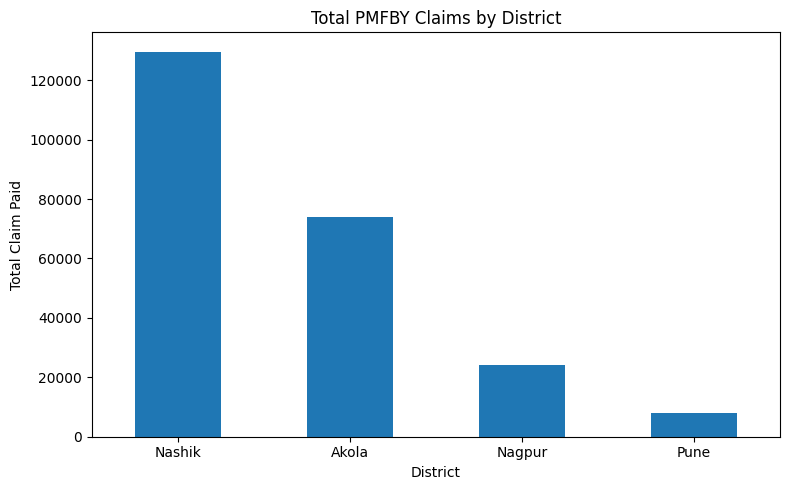

In [ ]:
district_claims = (
    df.groupby("District")["Total_Claim_Paid"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))
district_claims.plot(kind="bar")

plt.title("Total PMFBY Claims by District")
plt.xlabel("District")
plt.ylabel("Total Claim Paid")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


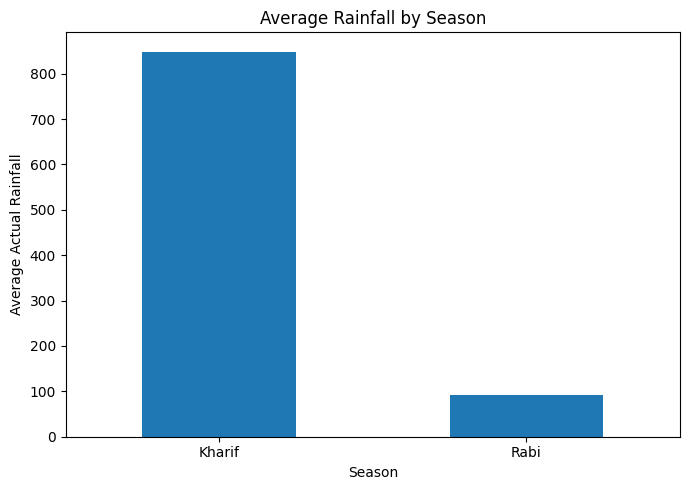

In [ ]:
season_rainfall = df.groupby("Season")["Actual_Rainfall"].mean()
plt.figure(figsize=(7,5))
season_rainfall.plot(kind="bar")
plt.title("Average Rainfall by Season")
plt.xlabel("Season")
plt.ylabel("Average Actual Rainfall")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


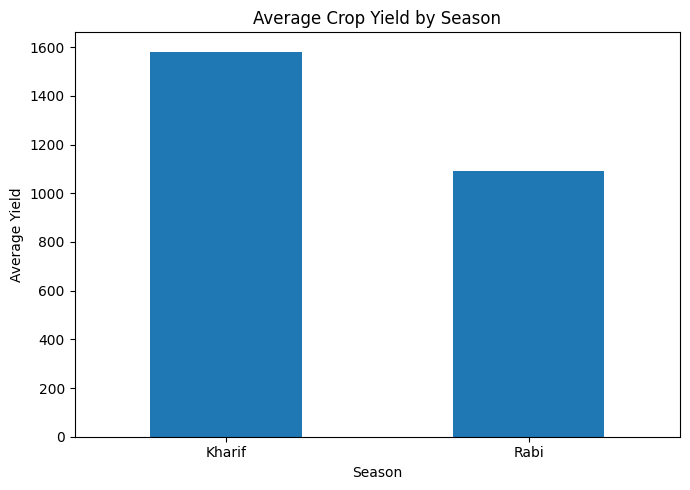

In [ ]:
season_yield = df.groupby("Season")["Yield"].mean()

plt.figure(figsize=(7,5))
season_yield.plot(kind="bar")

plt.title("Average Crop Yield by Season")
plt.xlabel("Season")
plt.ylabel("Average Yield")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


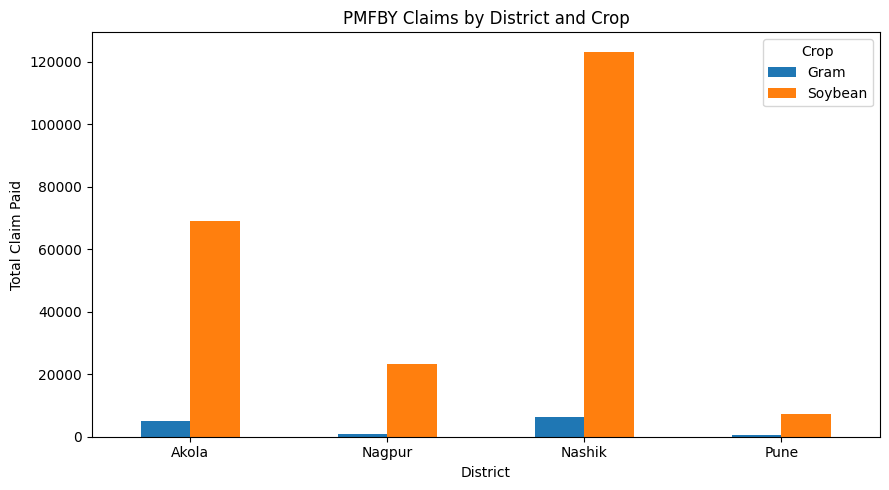

In [ ]:
district_crop_claims = (
    df.groupby(["District", "Crop"])["Total_Claim_Paid"]
    .sum()
    .unstack()
)
district_crop_claims.plot(kind="bar", figsize=(9,5))
plt.title("PMFBY Claims by District and Crop")
plt.xlabel("District")
plt.ylabel("Total Claim Paid")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
correlation = df["Departure_Percent"].corr(
df["Total_Claim_Paid"]
)
print("Correlation:", correlation)


Correlation: -0.08359373500530189
